# Kettle data for traditional meter vs smart meter

## Time series graph

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

#Graphs for smart meters

# With timestamp data and not seconds
def get_time_series_graph(file, row_start, row_end, title):
    file = pd.read_csv(file)

    filtered_data = file.loc[row_start:row_end].copy()
    filtered_data['last_changed'] = pd.to_datetime(filtered_data['last_changed'], errors='coerce')
    filtered_data['state'] = pd.to_numeric(filtered_data['state'], errors='coerce')

    plt.figure(figsize = (10,6))
    plt.plot(filtered_data['last_changed'], filtered_data['state'])
    plt.title(title)
    plt.xlabel('Timestamp(datetime)')
    plt.ylabel('energy consumptiong(W)')
    plt.grid()
    plt.show()

# Convert to seconds
def get_time_series_graph_seconds(file, row_start, row_end, title):
    new_file = pd.read_csv(file)

    filtered_data = new_file.loc[row_start:row_end].copy()
    filtered_data['last_changed'] = pd.to_datetime(filtered_data['last_changed'], errors='coerce')
    filtered_data = filtered_data.dropna(subset=['last_changed'])

    start_time = filtered_data['last_changed'].loc[row_start]
    filtered_data['seconds'] = (filtered_data['last_changed'] - start_time).dt.total_seconds()

    filtered_data['state'] = pd.to_numeric(filtered_data['state'], errors='coerce')

    plt.figure(figsize=(10, 6))
    plt.plot(filtered_data['seconds'], filtered_data['state'], linestyle='-')
    plt.title(title)
    plt.xlabel('Time (seconds)')
    plt.ylabel('State (Consumption)')
    plt.grid()
    plt.show()

#Utility function to clean and convert the data
def clean_filtered_data(row_start, filtered_data):
    filtered_data['last_changed'] = pd.to_datetime(filtered_data['last_changed'], errors='coerce')
    filtered_data = filtered_data.dropna(subset=['last_changed'])

    start_time = filtered_data['last_changed'].loc[row_start]
    filtered_data['seconds'] = (filtered_data['last_changed'] - start_time).dt.total_seconds()
    filtered_data['state'] = pd.to_numeric(filtered_data['state'], errors='coerce')
    return filtered_data

#Function to plot all experiments for smart meters
def plot_all_experiments(file, file2, file3, row_start, row_end, row_start2, row_end2, row_start3, row_end3, title):
    new_file = pd.read_csv(file)
    new_file2 = pd.read_csv(file2)
    new_file3 = pd.read_csv(file3)

    filtered_data = new_file.loc[row_start:row_end].copy()
    filtered_data = clean_filtered_data(row_start, filtered_data)

    filtered_data2 = new_file2.loc[row_start2:row_end2].copy()
    filtered_data2 = clean_filtered_data(row_start2, filtered_data2)

    filtered_data3 = new_file3.loc[row_start3:row_end3].copy()
    filtered_data3 = clean_filtered_data(row_start3, filtered_data3)
    
    plt.figure(figsize=(10, 6))
    plt.plot(filtered_data['seconds'], filtered_data['state'], label="Experiment 1", linestyle='-',  color='green')
    plt.plot(filtered_data2['seconds'], filtered_data2['state'], label="Experiment 2", linestyle='-',  color='red')
    plt.plot(filtered_data3['seconds'], filtered_data3['state'], label="Experiment 3", linestyle='-',  color='blue')
    plt.title(f"All {title} test result smart meter")
    plt.xlabel('Time (seconds)')
    plt.ylabel('Energy Consumption (Watts)')
    plt.grid()
    plt.legend()
    plt.show()


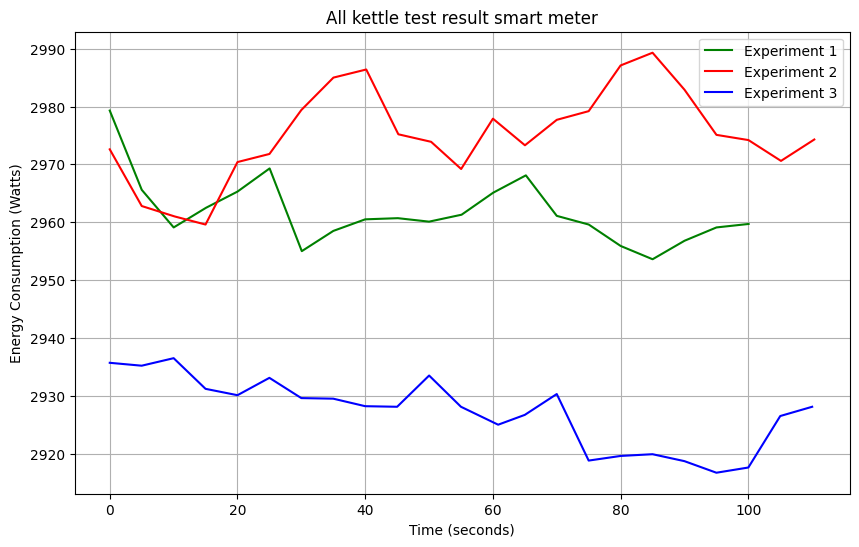

In [2]:
# Time series graph for all experiments
plot_all_experiments('csv_file_smart_meter/kettle/smart_meter_kettle_experiment_1.csv', 'csv_file_smart_meter/kettle/smart_meter_kettle_experiment_2.csv', 'csv_file_smart_meter/kettle/smart_meter_kettle_experiment_3.csv', 2,22,3,25,3,25, "kettle")

In [2]:
#Time series graph for all traditional meter results
def plot_trad_all(file, file2, file3, title):
    
    new_file = pd.read_csv(file)
    new_file2 = pd.read_csv(file2)
    new_file3 = pd.read_csv(file3)

    plt.figure(figsize=(8, 5))
    plt.plot(new_file['Second'], new_file['Smart_meter_reading'], label="Experiment 1", color="blue")
    plt.plot(new_file2['Second'], new_file2['Smart_meter_reading'], label="Experiment 2", color="red")
    plt.plot(new_file3['Second'], new_file3['Smart_meter_reading'], label="Experiment 3", color="green")
    plt.title(f"All {title} test result traditional meter")
    plt.xlabel("time(seconds)")
    plt.ylabel("energy consumption(Watts)")
    plt.grid(True)
    plt.legend()
    plt.show()

# plot experiment data for the trad meter
def plot_trad(file, title):
    
    new_file = pd.read_csv(file)
    
    plt.figure(figsize=(8, 5))
    plt.plot(new_file['Second'], new_file['Smart_meter_reading'], label="time series", color="blue")
    plt.title(f"Time series graph {title}")
    plt.xlabel("seconds")
    plt.ylabel("energy consumption(W)")
    plt.grid(True)
    plt.legend()
    plt.show()

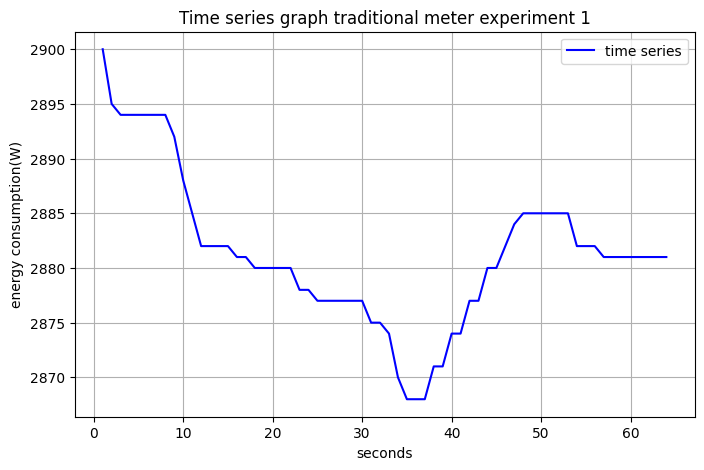

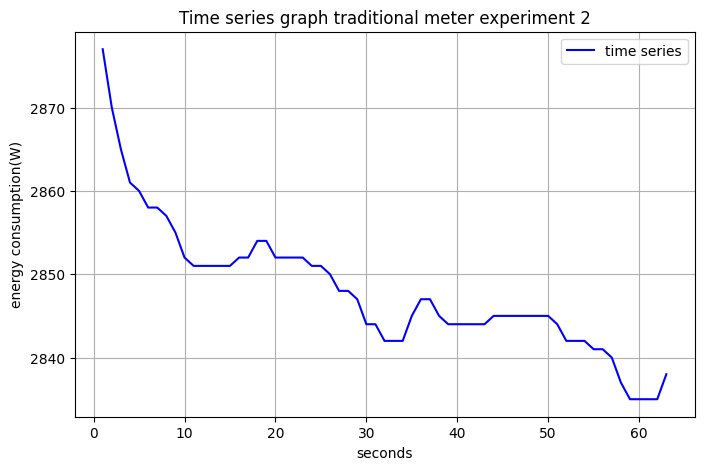

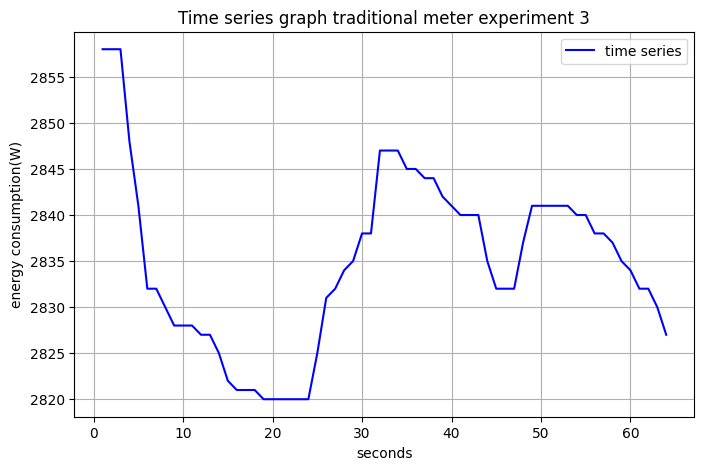

In [5]:

#Time series graph for traditional meters
plot_trad(file="csv_file_traditional/kettle/traditional_meter_kettle_exp1.csv", title="traditional meter experiment 1")
plot_trad(file="csv_file_traditional/kettle/traditional_meter_kettle_exp2.csv", title="traditional meter experiment 2")
plot_trad(file="csv_file_traditional/kettle/traditional_meter_kettle_exp3.csv", title="traditional meter experiment 3")

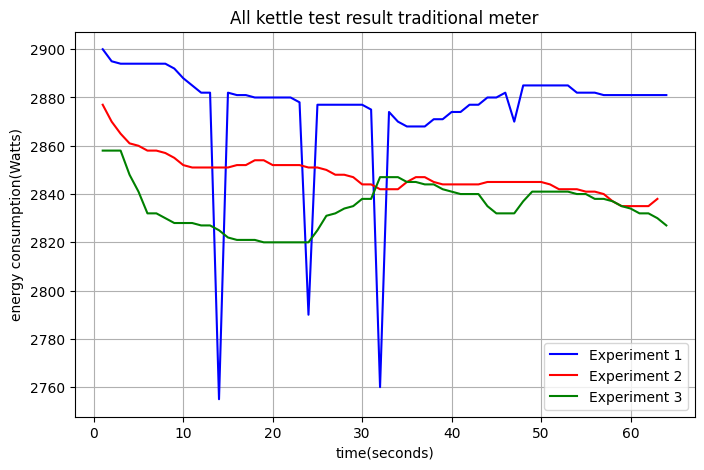

In [8]:
#All time series graph for traditional meter
plot_trad_all(file="csv_file_traditional/kettle/traditional_meter_kettle_exp1.csv", file2="csv_file_traditional/kettle/traditional_meter_kettle_exp2.csv", file3="csv_file_traditional/kettle/traditional_meter_kettle_exp3.csv", title="kettle")

## Gaussian distribution results

In [3]:
import numpy as np
from scipy.stats import norm

#plot pdf of experiment data in a combined dataset and then get the mean
def plot_pdf(file, file2, file3, row_start, row_end, row_start2, row_end2, row_start3, row_end3):
    new_file = pd.read_csv(file)
    new_file2 = pd.read_csv(file2)
    new_file3 = pd.read_csv(file3)

    filtered_data = new_file.loc[row_start:row_end].copy()
    filtered_data = clean_filtered_data(row_start, filtered_data)

    filtered_data2 = new_file2.loc[row_start2:row_end2].copy()
    filtered_data2 = clean_filtered_data(row_start2, filtered_data2)

    filtered_data3 = new_file3.loc[row_start3:row_end3].copy()
    filtered_data3 = clean_filtered_data(row_start3, filtered_data3)

    merged_vertical = pd.concat([filtered_data, filtered_data2, filtered_data3], ignore_index=True) 

    mean = merged_vertical['state'].mean()
    std_dev = merged_vertical['state'].std()

    print(f'mean: {mean}')
    print(f'std_dev: {std_dev}')

    x_values = np.linspace(merged_vertical["state"].min(), merged_vertical["state"].max(), 1000)
    y_values = norm.pdf(x_values, mean, std_dev)

    plt.figure(figsize=(8, 5))
    plt.plot(x_values, y_values, label="Gaussian Curve", color="blue")
    plt.title("Simple Gaussian Curve")
    plt.xlabel("X")
    plt.ylabel("Density")
    plt.grid(True)
    plt.legend()
    plt.show()

# plot experiment data for the traditional meter
def plot_pdf_trad(file, file2, file3):
    new_file = pd.read_csv(file)
    new_file2 = pd.read_csv(file2)
    new_file3 = pd.read_csv(file3)

    merged_vertical = pd.concat([new_file, new_file2, new_file3], ignore_index=True) 

    mean = merged_vertical['Smart_meter_reading'].mean()
    std_dev = merged_vertical['Smart_meter_reading'].std()

    print(f'mean: {mean}')
    print(f'std_dev: {std_dev}')

    x_values = np.linspace(merged_vertical["Smart_meter_reading"].min(), merged_vertical["Smart_meter_reading"].max(), 1000)
    y_values = norm.pdf(x_values, mean, std_dev)

    plt.figure(figsize=(8, 5))
    plt.plot(x_values, y_values, label="Gaussian Curve", color="blue")
    plt.title("Simple Gaussian Curve")
    plt.xlabel("X")
    plt.ylabel("Density")
    plt.grid(True)
    plt.legend()
    plt.show()

mean: 2954.5044776119403
std_dev: 21.61606748663165


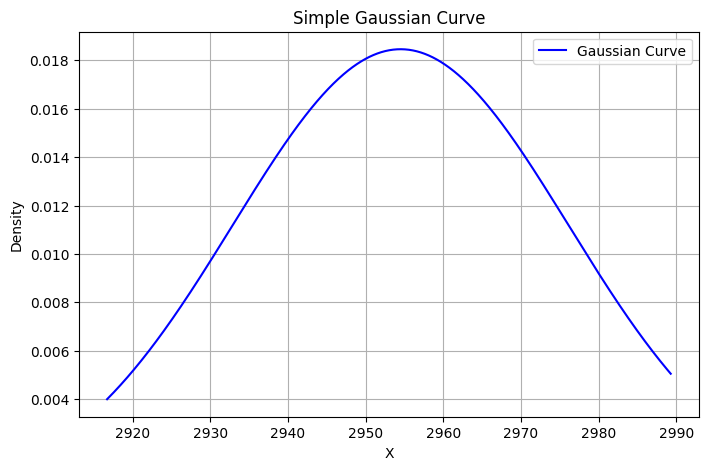

In [8]:
# pdf for all set of smart meter experiments
plot_pdf('csv_file_smart_meter/kettle/smart_meter_kettle_experiment_1.csv', 'csv_file_smart_meter/kettle/smart_meter_kettle_experiment_2.csv', 'csv_file_smart_meter/kettle/smart_meter_kettle_experiment_3.csv', 2,22,3,25,3,25)

mean: 2854.780104712042
std_dev: 21.27845023020953


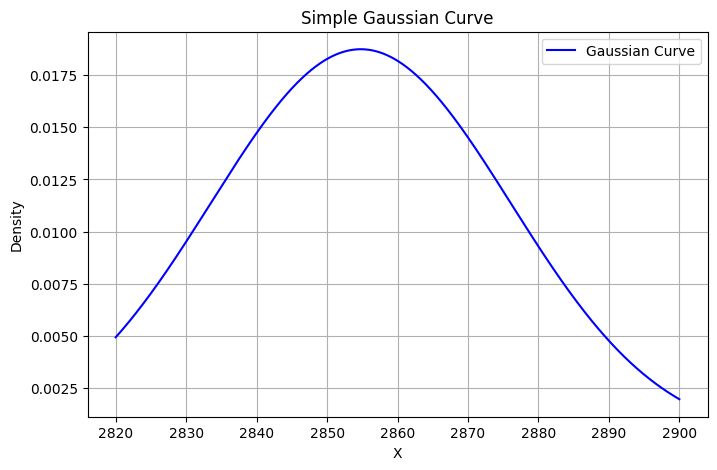

In [9]:
# traditional meter pdf 
plot_pdf_trad("csv_file_traditional/kettle/traditional_meter_kettle_exp1.csv", "csv_file_traditional/kettle/traditional_meter_kettle_exp2.csv", "csv_file_traditional/kettle/traditional_meter_kettle_exp3.csv")

## Multi model graphs featuring software meter vs traditional meters

mean of smart meter is: 2954.5044776119403
std of smart meter is: 21.61606748663165
mean of trad meter is: 2852.979057591623
std of trad meter is: 23.645620071820414


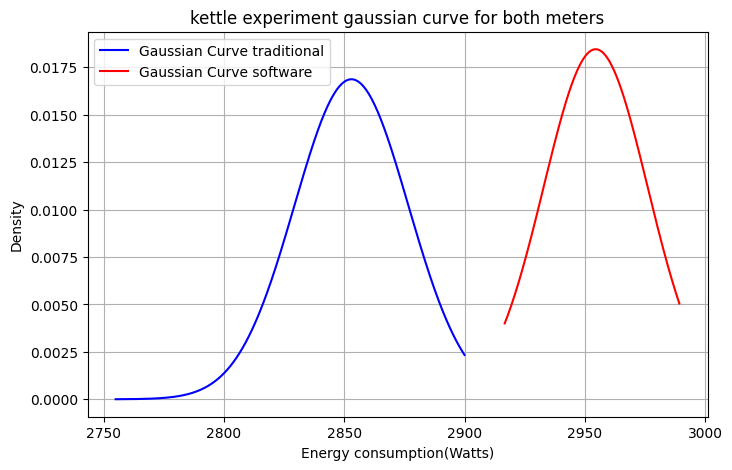

In [4]:
import numpy as np
from scipy.stats import norm
# collab the trad and software meter data and plot them in 1 paragraph

def collab_graph(file, file2, file3, sfw_file, sfw_file2, sfw_file3, row_start, row_end, row_start2, row_end2, row_start3, row_end3, title):
    # Software meters
    new_file_sfw = pd.read_csv(sfw_file)
    new_file_sfw2 = pd.read_csv(sfw_file2)
    new_file_sfw3 = pd.read_csv(sfw_file3)

    # Traditional meters
    new_file = pd.read_csv(file)
    new_file2 = pd.read_csv(file2)
    new_file3 = pd.read_csv(file3)

    filtered_data = new_file_sfw.loc[row_start:row_end].copy()
    filtered_data = clean_filtered_data(row_start, filtered_data)

    filtered_data2 = new_file_sfw2.loc[row_start2:row_end2].copy()
    filtered_data2 = clean_filtered_data(row_start2, filtered_data2)

    filtered_data3 = new_file_sfw3.loc[row_start3:row_end3].copy()
    filtered_data3 = clean_filtered_data(row_start3, filtered_data3)

    merged_verticle = pd.concat([new_file, new_file2, new_file3], ignore_index=True) 
    merged_verticle_sfw = pd.concat([filtered_data, filtered_data2, filtered_data3], ignore_index=True) 

    mean_sfw = merged_verticle_sfw['state'].mean()
    std_dev_sfw = merged_verticle_sfw['state'].std()

    mean = merged_verticle['Smart_meter_reading'].mean()
    std_dev = merged_verticle['Smart_meter_reading'].std()

    x_values_sfw = np.linspace(merged_verticle_sfw["state"].min(), merged_verticle_sfw["state"].max(), 1000)
    y_values_sfw = norm.pdf(x_values_sfw, mean_sfw, std_dev_sfw)

    x_values = np.linspace(merged_verticle["Smart_meter_reading"].min(), merged_verticle["Smart_meter_reading"].max(), 1000)
    y_values = norm.pdf(x_values, mean, std_dev)

    print(f'mean of smart meter is: {mean_sfw}')
    print(f'std of smart meter is: {std_dev_sfw}')

    print(f'mean of trad meter is: {mean}')
    print(f'std of trad meter is: {std_dev}')

    plt.figure(figsize=(8, 5))
    plt.plot(x_values, y_values, label="Gaussian Curve traditional", color="blue")
    plt.plot(x_values_sfw, y_values_sfw, label="Gaussian Curve software", color="red")
    plt.title(f"{title} experiment gaussian curve for both meters")
    plt.xlabel("Energy consumption(Watts)")
    plt.ylabel("Density")
    plt.grid(True)
    plt.legend()
    plt.show()


# distribution in 1 set
collab_graph("csv_file_traditional/kettle/traditional_meter_kettle_exp1.csv", "csv_file_traditional/kettle/traditional_meter_kettle_exp2.csv", "csv_file_traditional/kettle/traditional_meter_kettle_exp3.csv", 'csv_file_smart_meter/kettle/smart_meter_kettle_experiment_1.csv', 'csv_file_smart_meter/kettle/smart_meter_kettle_experiment_2.csv', 'csv_file_smart_meter/kettle/smart_meter_kettle_experiment_3.csv', 2,22,3,25,3,25, "kettle")

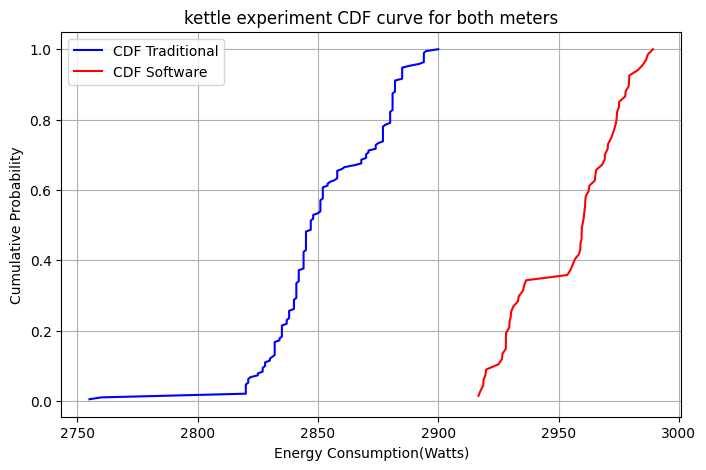

In [5]:
# collab the trad and software meter data and plot them in 1 paragraph

def collab_graph_cdf(file, file2, file3, sfw_file, sfw_file2, sfw_file3, row_start, row_end, row_start2, row_end2, row_start3, row_end3, title):
    # Software meters
    new_file_sfw = pd.read_csv(sfw_file)
    new_file_sfw2 = pd.read_csv(sfw_file2)
    new_file_sfw3 = pd.read_csv(sfw_file3)

    # Traditional meters
    new_file = pd.read_csv(file)
    new_file2 = pd.read_csv(file2)
    new_file3 = pd.read_csv(file3)

    filtered_data = new_file_sfw.loc[row_start:row_end].copy()
    filtered_data = clean_filtered_data(row_start, filtered_data)

    filtered_data2 = new_file_sfw2.loc[row_start2:row_end2].copy()
    filtered_data2 = clean_filtered_data(row_start2, filtered_data2)

    filtered_data3 = new_file_sfw3.loc[row_start3:row_end3].copy()
    filtered_data3 = clean_filtered_data(row_start3, filtered_data3)

    merged_verticle = pd.concat([new_file, new_file2, new_file3], ignore_index=True) 
    merged_verticle_sfw = pd.concat([filtered_data, filtered_data2, filtered_data3], ignore_index=True) 

    # Sort data for CDF calculation
    traditional_sorted = merged_verticle["Smart_meter_reading"].sort_values()
    software_sorted = merged_verticle_sfw["state"].sort_values()

    # Calculate CDF
    traditional_cdf = np.arange(1, len(traditional_sorted) + 1) / len(traditional_sorted)
    software_cdf = np.arange(1, len(software_sorted) + 1) / len(software_sorted)

    plt.figure(figsize=(8, 5))
    plt.plot(traditional_sorted, traditional_cdf, label="CDF Traditional", color="blue")
    plt.plot(software_sorted, software_cdf, label="CDF Software", color="red")
    plt.title(f"{title} experiment CDF curve for both meters")
    plt.xlabel("Energy Consumption(Watts)")
    plt.ylabel("Cumulative Probability")
    plt.grid(True)
    plt.legend()
    plt.show()

# cdf -> tells us probability before 1 point(f(x) -> tell us probability of points before x)
collab_graph_cdf("csv_file_traditional/kettle/traditional_meter_kettle_exp1.csv", "csv_file_traditional/kettle/traditional_meter_kettle_exp2.csv", "csv_file_traditional/kettle/traditional_meter_kettle_exp3.csv", 'csv_file_smart_meter/kettle/smart_meter_kettle_experiment_1.csv', 'csv_file_smart_meter/kettle/smart_meter_kettle_experiment_2.csv', 'csv_file_smart_meter/kettle/smart_meter_kettle_experiment_3.csv', 2,22,3,25,3,25, "kettle")


In [6]:
# Function to plot everything so no need to manually do shit
def plot_all_graphs_everything(file1, file2, file3, file1_sfw, file2_sfw, file3_sfw, f1_start, f1_end, f2_start, f2_end, f3_start, f3_end):
    plot_all_experiments(file1_sfw, file2_sfw, file3_sfw, f1_start, f1_end, f2_start, f2_end, f3_start, f3_end)
    plot_trad_all(file1, file2, file3)
    collab_graph(file1, file2, file3, file1_sfw, file2_sfw, file3_sfw, f1_start, f1_end, f2_start, f2_end, f3_start, f3_end)
    collab_graph_cdf(file1, file2, file3, file1_sfw, file2_sfw, file3_sfw, f1_start, f1_end, f2_start, f2_end, f3_start, f3_end)

## Rice cooker data for traditional meter vs smart meter

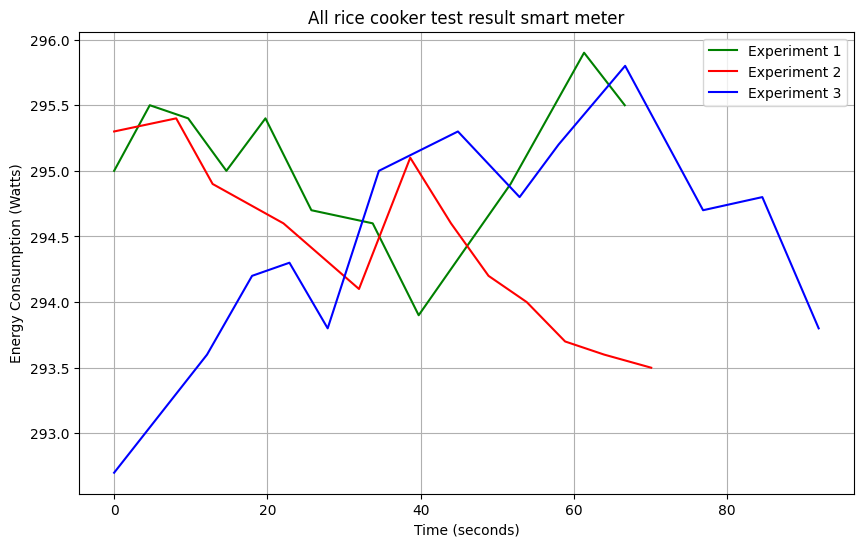

In [8]:
plot_all_experiments('csv_file_smart_meter/rice_cooker/rice_cooker_exp.csv', 'csv_file_smart_meter/rice_cooker/rice_cooker_exp.csv', 'csv_file_smart_meter/rice_cooker/rice_cooker_exp2.csv', 6,17,21,32,4,16, "rice cooker")

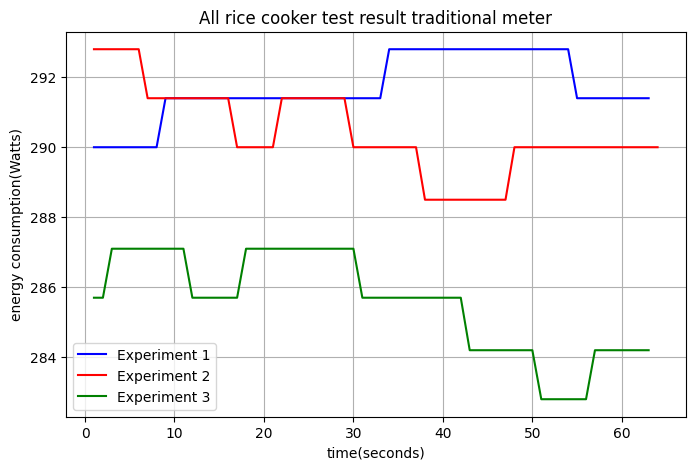

In [10]:
plot_trad_all(file="csv_file_traditional/rice_cooker/traditional_meter_rice_cooker_exp_1.csv", file2="csv_file_traditional/rice_cooker/traditional_meter_rice_cooker_exp_2.csv", file3="csv_file_traditional/rice_cooker/traditional_meter_rice_cooker_exp_3.csv", title="rice cooker")

mean of smart meter is: 294.627027027027
std of smart meter is: 0.7350920761104395
mean of trad meter is: 289.2284210526316
std of trad meter is: 2.903607067368247


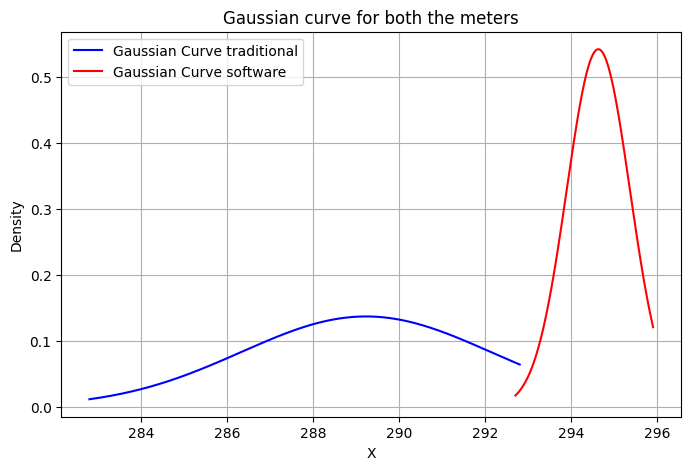

In [13]:
collab_graph("csv_file_traditional/rice_cooker/traditional_meter_rice_cooker_exp_1.csv", "csv_file_traditional/rice_cooker/traditional_meter_rice_cooker_exp_2.csv", "csv_file_traditional/rice_cooker/traditional_meter_rice_cooker_exp_3.csv", 'csv_file_smart_meter/rice_cooker/rice_cooker_exp.csv', 'csv_file_smart_meter/rice_cooker/rice_cooker_exp.csv', 'csv_file_smart_meter/rice_cooker/rice_cooker_exp2.csv', 6,17,21,32,4,16)

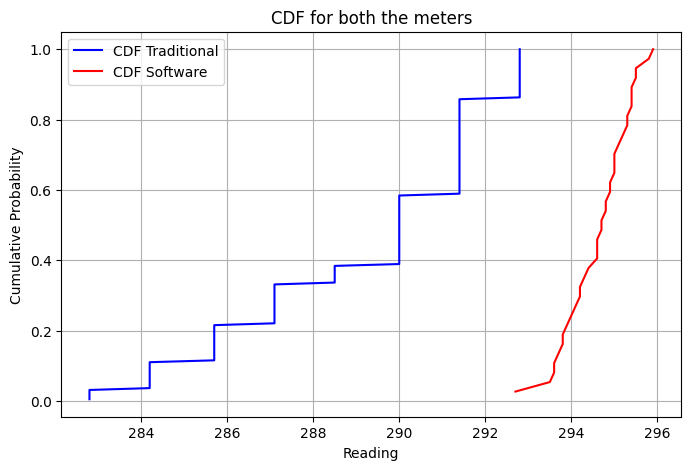

In [16]:
collab_graph_cdf("csv_file_traditional/rice_cooker/traditional_meter_rice_cooker_exp_1.csv", "csv_file_traditional/rice_cooker/traditional_meter_rice_cooker_exp_2.csv", "csv_file_traditional/rice_cooker/traditional_meter_rice_cooker_exp_3.csv", 'csv_file_smart_meter/rice_cooker/rice_cooker_exp.csv', 'csv_file_smart_meter/rice_cooker/rice_cooker_exp.csv', 'csv_file_smart_meter/rice_cooker/rice_cooker_exp2.csv', 6,17,21,32,4,16)

## Toaster data for traditional meter vs smart meter

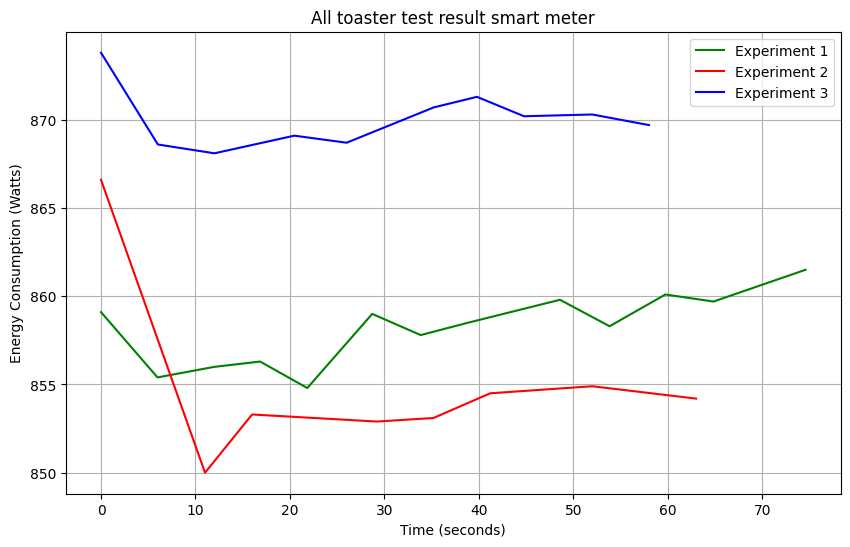

In [12]:
plot_all_experiments('csv_file_smart_meter/toaster/toaster_exp_1.csv', 'csv_file_smart_meter/toaster/toaster_exp_2.csv', 'csv_file_smart_meter/toaster/toaster_exp_3.csv',3,15,1,8,2,11, 'toaster')

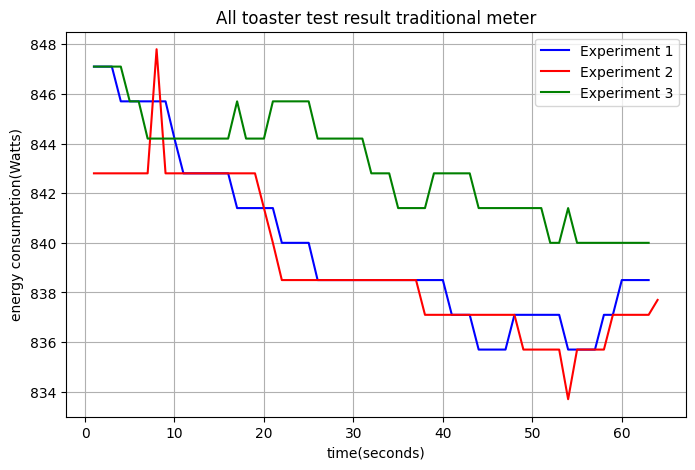

In [13]:
# Traditional meter
plot_trad_all(file="csv_file_traditional/toaster/traditional_meter_toaster_exp1.csv", file2="csv_file_traditional/toaster/traditional_meter_toaster_exp2.csv", file3="csv_file_traditional/toaster/traditional_meter_toaster_exp3.csv", title='toaster')

mean of smart meter is: 861.1709677419356
std of smart meter is: 6.978165639974796
mean of trad meter is: 840.6578947368421
std of trad meter is: 3.3272827290795983


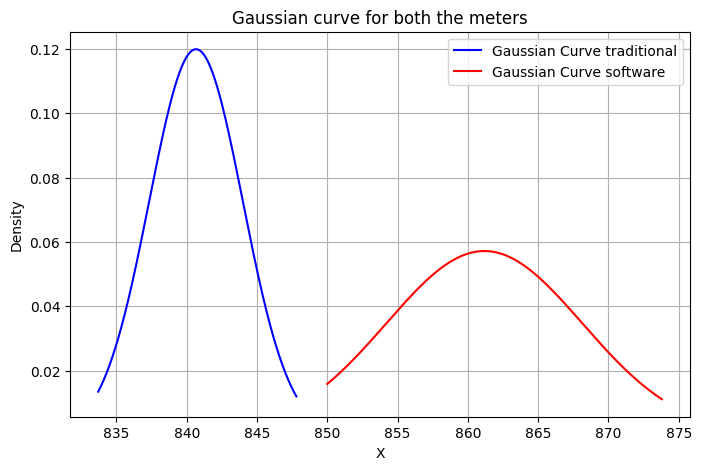

In [27]:
collab_graph("csv_file_traditional/toaster/traditional_meter_toaster_exp1.csv", "csv_file_traditional/toaster/traditional_meter_toaster_exp2.csv", "csv_file_traditional/toaster/traditional_meter_toaster_exp3.csv", 'csv_file_smart_meter/toaster/toaster_exp_1.csv', 'csv_file_smart_meter/toaster/toaster_exp_2.csv', 'csv_file_smart_meter/toaster/toaster_exp_3.csv',3,15,1,8,2,11)

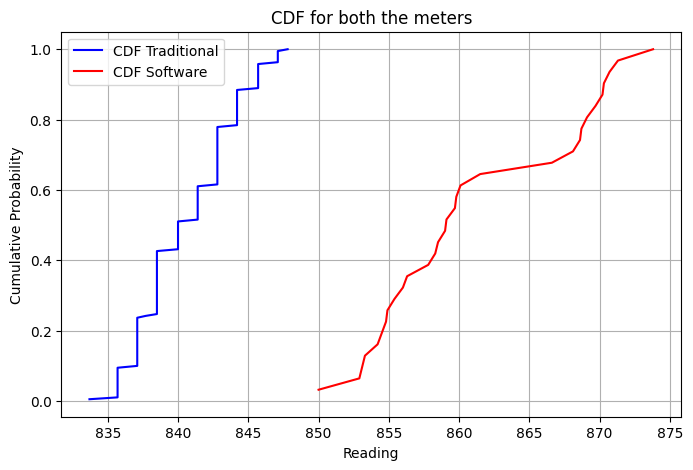

In [28]:
collab_graph_cdf("csv_file_traditional/toaster/traditional_meter_toaster_exp1.csv", "csv_file_traditional/toaster/traditional_meter_toaster_exp2.csv", "csv_file_traditional/toaster/traditional_meter_toaster_exp3.csv", 'csv_file_smart_meter/toaster/toaster_exp_1.csv', 'csv_file_smart_meter/toaster/toaster_exp_2.csv', 'csv_file_smart_meter/toaster/toaster_exp_3.csv',3,15,1,8,2,11)

In [15]:
# Function to plot everything so no need to manually do shit
def plot_all_graphs_everything(file1, file2, file3, file1_sfw, file2_sfw, file3_sfw, f1_start, f1_end, f2_start, f2_end, f3_start, f3_end, title):
    plot_all_experiments(file1_sfw, file2_sfw, file3_sfw, f1_start, f1_end, f2_start, f2_end, f3_start, f3_end, title)
    plot_trad_all(file1, file2, file3, title)
    collab_graph(file1, file2, file3, file1_sfw, file2_sfw, file3_sfw, f1_start, f1_end, f2_start, f2_end, f3_start, f3_end, title)
    collab_graph_cdf(file1, file2, file3, file1_sfw, file2_sfw, file3_sfw, f1_start, f1_end, f2_start, f2_end, f3_start, f3_end, title)

## Mobile phone traditional meter vs smart meter

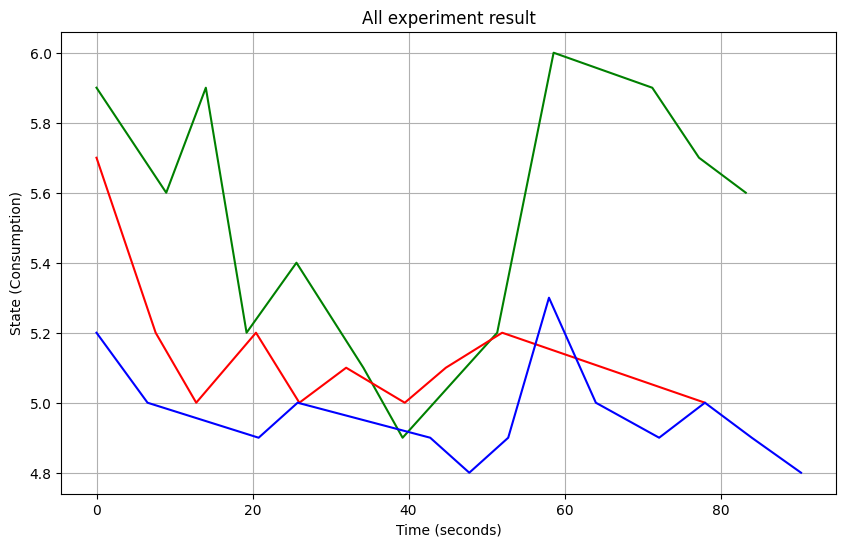

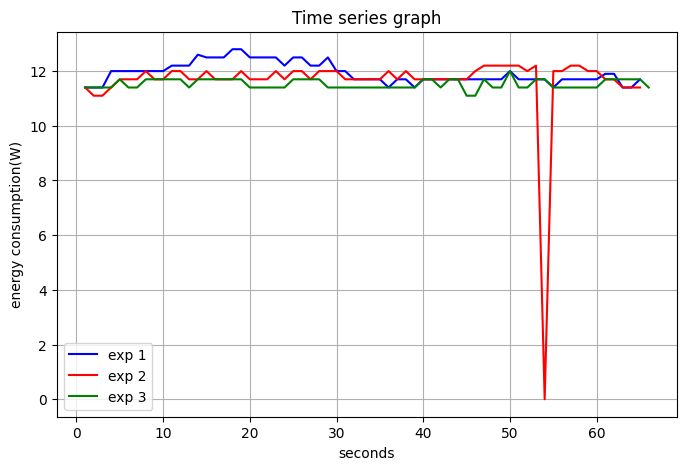

mean of smart meter is: 5.214285714285715
std of smart meter is: 0.35074949762477725
mean of trad meter is: 11.694897959183676
std of trad meter is: 0.9017217091854484


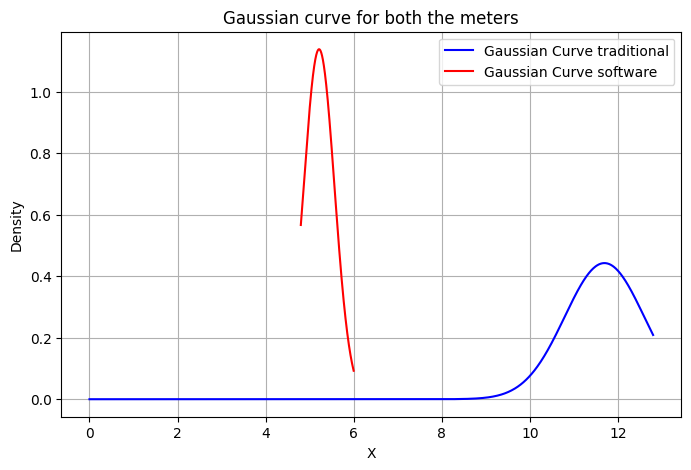

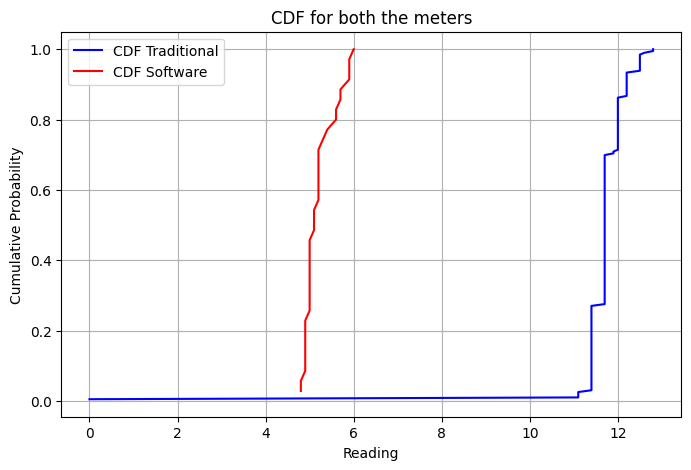

In [35]:
plot_all_graphs_everything('csv_file_traditional/iphone/traditional_meter_iphone_exp1.csv', 'csv_file_traditional/iphone/traditional_meter_iphone_exp2.csv', 'csv_file_traditional/iphone/traditional_meter_iphone_exp3.csv', 'csv_file_smart_meter/iphone/iphone_exp1.csv', 'csv_file_smart_meter/iphone/iphone_exp2.csv', 'csv_file_smart_meter/iphone/iphone_exp3.csv', 3,14,3,12,3,15)

## Smart watch traditional meter vs smart meter

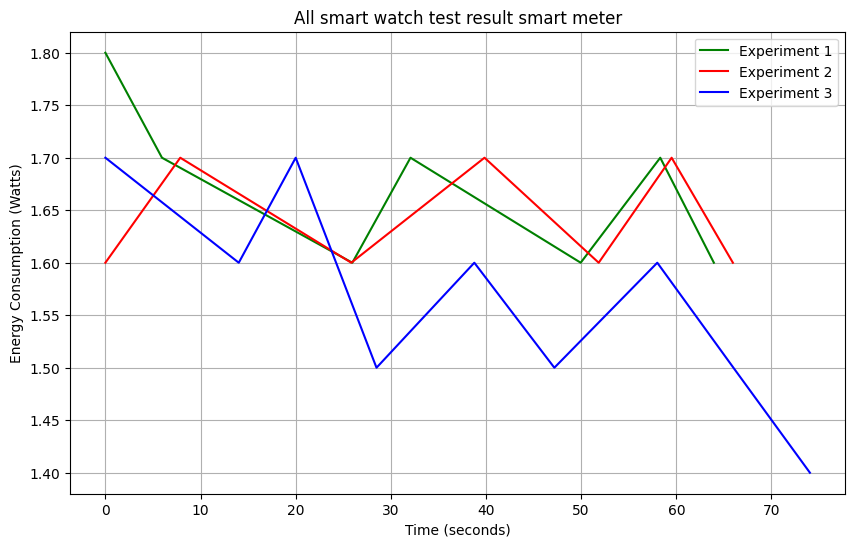

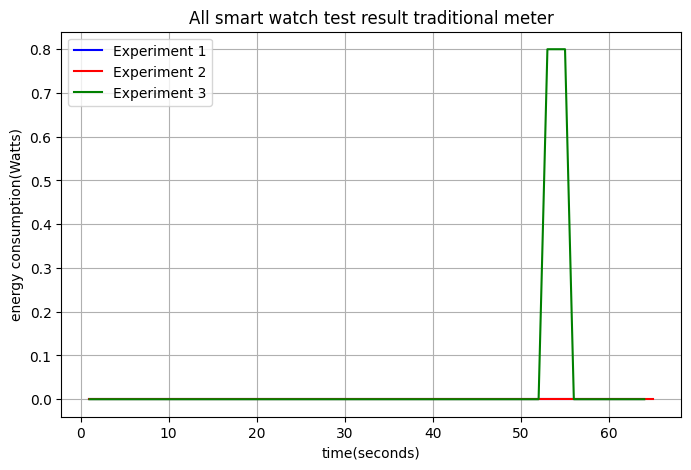

mean of smart meter is: 1.6217391304347826
std of smart meter is: 0.09023465237988439
mean of trad meter is: 0.012435233160621763
std of trad meter is: 0.0992197540084243


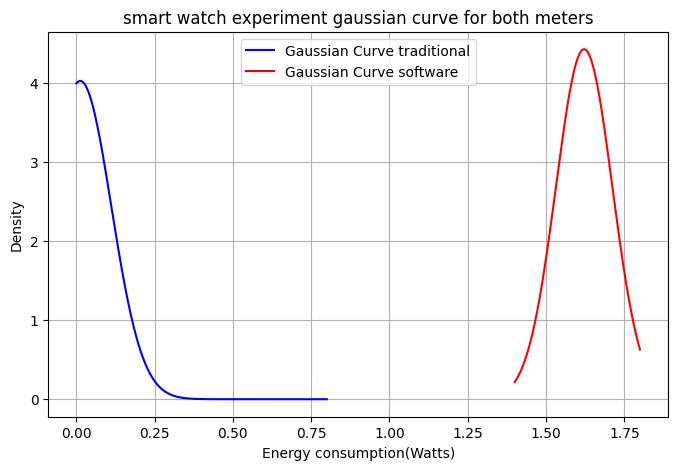

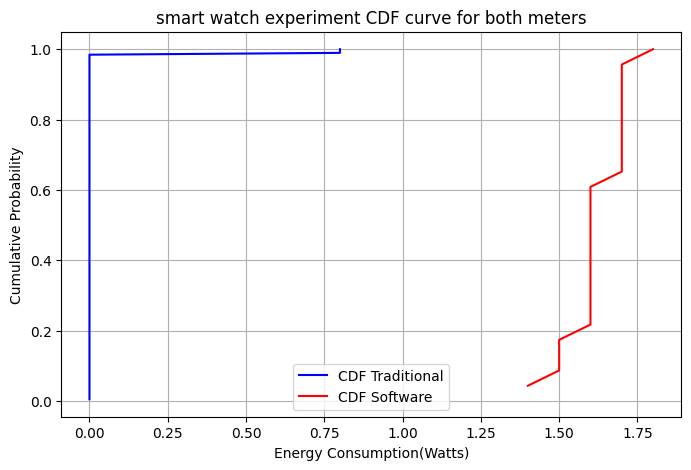

In [16]:
plot_all_graphs_everything('csv_file_traditional/watch/traditional_meter_watch_exp1.csv', 'csv_file_traditional/watch/traditional_meter_watch_exp2.csv', 'csv_file_traditional/watch/traditional_meter_watch_exp3.csv', 'csv_file_smart_meter/smart_watch/watch_exp1.csv', 'csv_file_smart_meter/smart_watch/watch_exp2.csv', 'csv_file_smart_meter/smart_watch/watch_exp3.csv', 4,10,6,12,6,14, "smart watch")

In [24]:
def get_mean_trad(file1, file2, file3):
    new_file1 = pd.read_csv(file1)
    new_file2 = pd.read_csv(file2)
    new_file3 = pd.read_csv(file3)
    merged_vertical = pd.concat([new_file1, new_file2, new_file3], ignore_index=True) 

    mean = merged_vertical['Smart_meter_reading'].mean()
    std = merged_vertical['Smart_meter_reading'].std()
    print(file1)
    return mean, std

def get_mean_sfw(file1, file2, file3, f1_start, f1_end, f2_start,f2_end, f3_start, f3_end):
    new_file1 = pd.read_csv(file1)
    new_file2 = pd.read_csv(file2)
    new_file3 = pd.read_csv(file3)
    filtered_data = new_file1.loc[f1_start:f1_end].copy()
    filtered_data = clean_filtered_data(f1_start, filtered_data)

    filtered_data2 = new_file2.loc[f2_start:f2_end].copy()
    filtered_data2 = clean_filtered_data(f2_start, filtered_data2)

    filtered_data3 = new_file3.loc[f3_start:f3_end].copy()
    filtered_data3 = clean_filtered_data(f3_start, filtered_data3)

    merged_vertical = pd.concat([filtered_data, filtered_data2, filtered_data3], ignore_index=True) 

    mean = merged_vertical['state'].mean()
    std = merged_vertical['state'].std()
    return mean, std

# Laptop idle state smart meter vs traditional meter

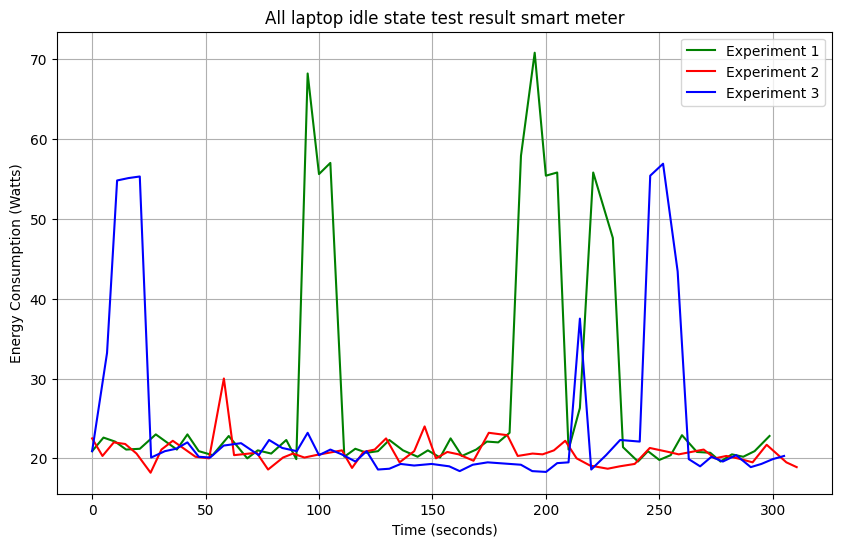

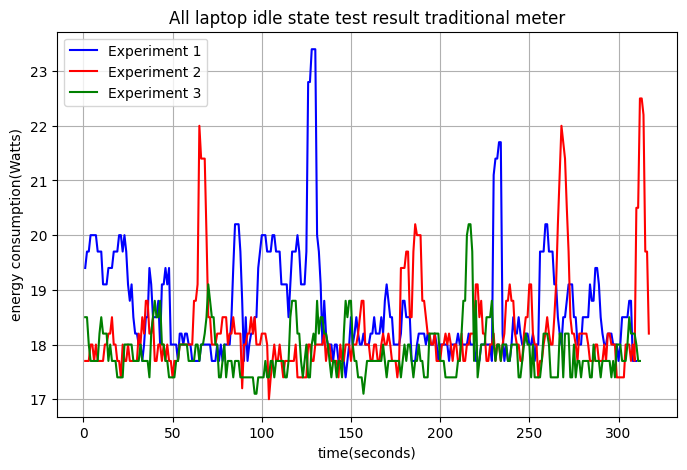

mean of smart meter is: 24.187730061349694
std of smart meter is: 10.667915279964989
mean of trad meter is: 18.249946751863682
std of trad meter is: 0.8737388092310517


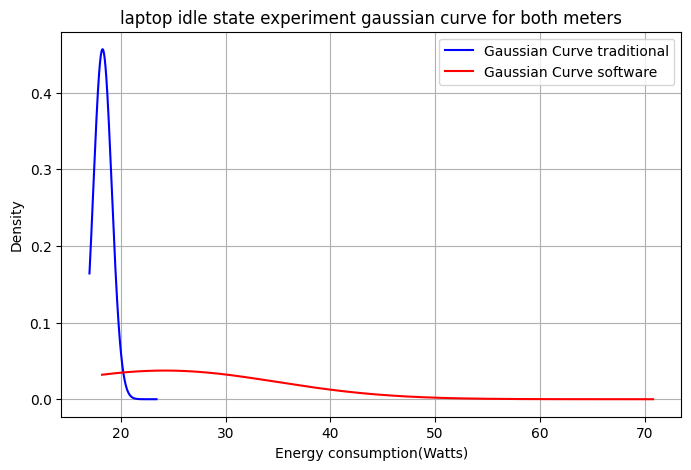

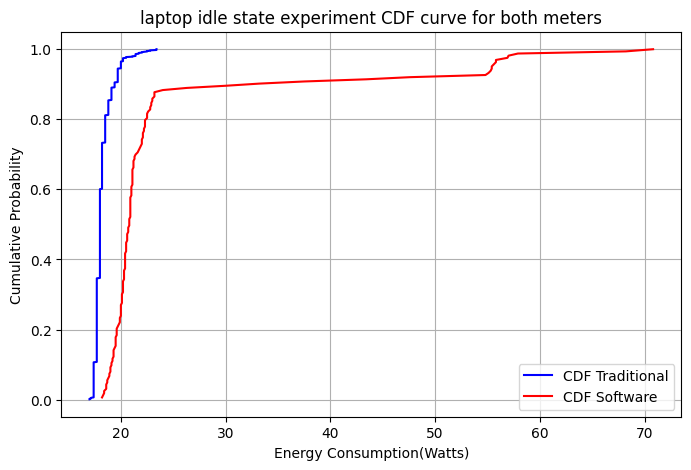

In [17]:
plot_all_graphs_everything('csv_file_traditional/traditional_meter_idle_exp1.csv', 'csv_file_traditional/traditional_meter_idle_exp2.csv', 'csv_file_traditional/traditional_meter_idle_exp3.csv', 'csv_file_smart_meter/software_test_idle_state/smart_meter_idle_state_exp_1.csv', 'csv_file_smart_meter/software_test_idle_state/smart_meter_idle_state_exp_2.csv', 'csv_file_smart_meter/software_test_idle_state/smart_meter_idle_state_exp_3.csv', 2,58,2,57,2,57, "laptop idle state")

csv_file_traditional/kettle/traditional_meter_kettle_exp1.csv
csv_file_traditional/iphone/traditional_meter_iphone_exp1.csv
csv_file_traditional/rice_cooker/traditional_meter_rice_cooker_exp_1.csv
csv_file_traditional/watch/traditional_meter_watch_exp1.csv
csv_file_traditional/rice_cooker/traditional_meter_rice_cooker_exp_1.csv
csv_file_traditional/traditional_meter_idle_exp1.csv
csv_file_traditional/traditional_meter_server_up_exp1.csv
csv_file_traditional/traditional_meter_game_exp1.csv
csv_file_traditional/traditional_meter_cpu_stresser_exp1.csv
[23.645620071820414, 0.9017217091854484, 2.903607067368247, 0.0992197540084243, 2.903607067368247, 0.9759359111077136, 6.728955209686445, 25.20002341316817, 27.862093549252567]
[21.61606748663165, 0.35074949762477725, 0.7350920761104395, 0.09023465237988439, 6.978165639974796, 10.667915279964989, 7.776151175093119, 2.8113910878142176, 2.709488724384167]


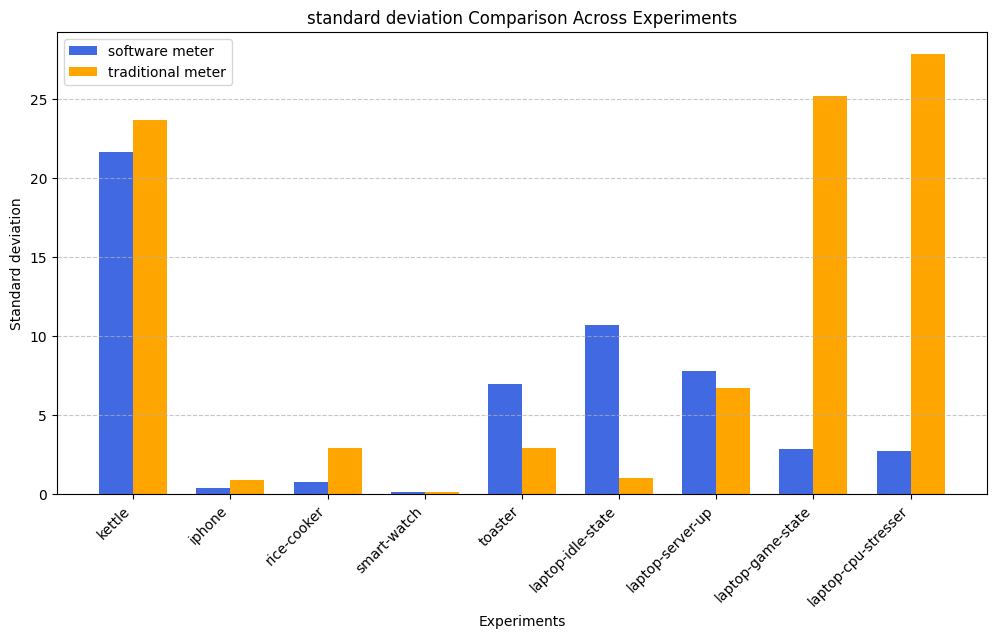

In [30]:
#std dev results
def get_bar_chart_for_std_dev():
    sfw_std = [
        get_mean_sfw('csv_file_smart_meter/kettle/smart_meter_kettle_experiment_1.csv', 'csv_file_smart_meter/kettle/smart_meter_kettle_experiment_2.csv', 'csv_file_smart_meter/kettle/smart_meter_kettle_experiment_3.csv', 2,22,3,25,3,25)[1],
        get_mean_sfw('csv_file_smart_meter/iphone/iphone_exp1.csv', 'csv_file_smart_meter/iphone/iphone_exp2.csv', 'csv_file_smart_meter/iphone/iphone_exp3.csv', 3,14,3,12,3,15)[1],
        get_mean_sfw('csv_file_smart_meter/rice_cooker/rice_cooker_exp.csv', 'csv_file_smart_meter/rice_cooker/rice_cooker_exp.csv', 'csv_file_smart_meter/rice_cooker/rice_cooker_exp2.csv', 6,17,21,32,4,16)[1],
        get_mean_sfw('csv_file_smart_meter/smart_watch/watch_exp1.csv', 'csv_file_smart_meter/smart_watch/watch_exp2.csv', 'csv_file_smart_meter/smart_watch/watch_exp3.csv', 4,10,6,12,6,14)[1],
        get_mean_sfw('csv_file_smart_meter/toaster/toaster_exp_1.csv', 'csv_file_smart_meter/toaster/toaster_exp_2.csv', 'csv_file_smart_meter/toaster/toaster_exp_3.csv',3,15,1,8,2,11)[1],
        get_mean_sfw('csv_file_smart_meter/software_test_idle_state/smart_meter_idle_state_exp_1.csv', 'csv_file_smart_meter/software_test_idle_state/smart_meter_idle_state_exp_2.csv', 'csv_file_smart_meter/software_test_idle_state/smart_meter_idle_state_exp_3.csv', 2,58,2,57,2,57)[1],
        get_mean_sfw('csv_file_smart_meter/software_test_server_up_state/smart_meter_server_up_exp_1.csv', 'csv_file_smart_meter/software_test_server_up_state/smart_meter_server_up_exp_2.csv', 'csv_file_smart_meter/software_test_server_up_state/smart_meter_server_up_exp_3.csv', 2,44,2,60,2,49)[1],
        get_mean_sfw('csv_file_smart_meter/software_test_gaming_state/smart_meter_gaming_state_exp_1.csv', 'csv_file_smart_meter/software_test_gaming_state/smart_meter_gaming_state_exp_2.csv', 'csv_file_smart_meter/software_test_gaming_state/smart_meter_gaming_state_exp_3.csv', 2,54,2,49,2,59)[1],
        get_mean_sfw('csv_file_smart_meter/above_normal_threading_16_processor_state/smart_meter_above_normal_threading_16_processors_exp_1.csv', 'csv_file_smart_meter/above_normal_threading_16_processor_state/smart_meter_above_normal_threading_16_processors_exp_2.csv', 'csv_file_smart_meter/above_normal_threading_16_processor_state/smart_meter_above_normal_threading_16_processors_exp_3.csv', 2,61,2,58,2,64)[1]
    ]

    trad_std = [
        get_mean_trad(file1="csv_file_traditional/kettle/traditional_meter_kettle_exp1.csv", file2="csv_file_traditional/kettle/traditional_meter_kettle_exp2.csv", file3="csv_file_traditional/kettle/traditional_meter_kettle_exp3.csv")[1],
        get_mean_trad('csv_file_traditional/iphone/traditional_meter_iphone_exp1.csv','csv_file_traditional/iphone/traditional_meter_iphone_exp2.csv', 'csv_file_traditional/iphone/traditional_meter_iphone_exp3.csv')[1],
        get_mean_trad(file1="csv_file_traditional/rice_cooker/traditional_meter_rice_cooker_exp_1.csv", file2="csv_file_traditional/rice_cooker/traditional_meter_rice_cooker_exp_2.csv", file3="csv_file_traditional/rice_cooker/traditional_meter_rice_cooker_exp_3.csv")[1],
        get_mean_trad('csv_file_traditional/watch/traditional_meter_watch_exp1.csv', 'csv_file_traditional/watch/traditional_meter_watch_exp2.csv', 'csv_file_traditional/watch/traditional_meter_watch_exp3.csv')[1],
        get_mean_trad('csv_file_traditional/rice_cooker/traditional_meter_rice_cooker_exp_1.csv', 'csv_file_traditional/rice_cooker/traditional_meter_rice_cooker_exp_2.csv', 'csv_file_traditional/rice_cooker/traditional_meter_rice_cooker_exp_3.csv')[1],
        get_mean_trad('csv_file_traditional/traditional_meter_idle_exp1.csv', 'csv_file_traditional/traditional_meter_idle_exp2.csv', 'csv_file_traditional/traditional_meter_idle_exp1.csv')[1],
        get_mean_trad('csv_file_traditional/traditional_meter_server_up_exp1.csv', 'csv_file_traditional/traditional_meter_server_up_exp2.csv', 'csv_file_traditional/traditional_meter_server_up_exp3.csv')[1],
        get_mean_trad('csv_file_traditional/traditional_meter_game_exp1.csv', 'csv_file_traditional/traditional_meter_game_exp2.csv', 'csv_file_traditional/traditional_meter_game_exp3.csv')[1],
        get_mean_trad('csv_file_traditional/traditional_meter_cpu_stresser_exp1.csv', 'csv_file_traditional/traditional_meter_cpu_stresser_exp2.csv', 'csv_file_traditional/traditional_meter_cpu_stresser_exp3.csv')[1]
    ]

    print(trad_std)
    print(sfw_std)

    experiments = ['kettle', 'iphone', 'rice-cooker', 'smart-watch', 'toaster', 'laptop-idle-state', 'laptop-server-up', 'laptop-game-state', 'laptop-cpu-stresser']
    x = np.arange(len(experiments))
    width = 0.35

    fig, ax = plt.subplots(figsize=(12, 6))
    ax.bar(x - width/2, sfw_std, width, label='software meter', color='royalblue')
    ax.bar(x + width/2, trad_std, width, label='traditional meter', color='orange')

    ax.set_xlabel("Experiments")
    ax.set_ylabel("Standard deviation")
    ax.set_title("standard deviation Comparison Across Experiments")
    ax.set_xticks(x)
    ax.set_xticklabels(experiments, rotation=45, ha="right")
    ax.legend()
    ax.grid(axis='y', linestyle='--', alpha=0.7)
    
    # Show plot
    plt.show()


get_bar_chart_for_std_dev()

# traditional vs smart meter server up state

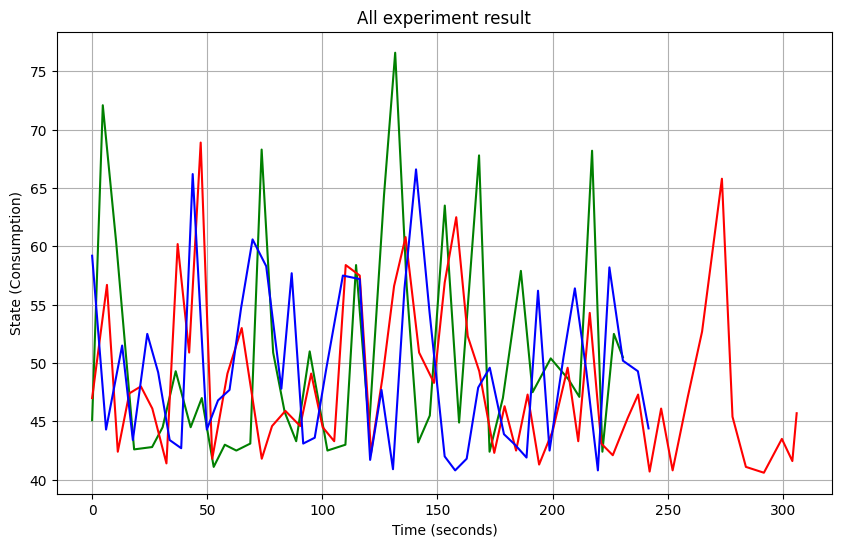

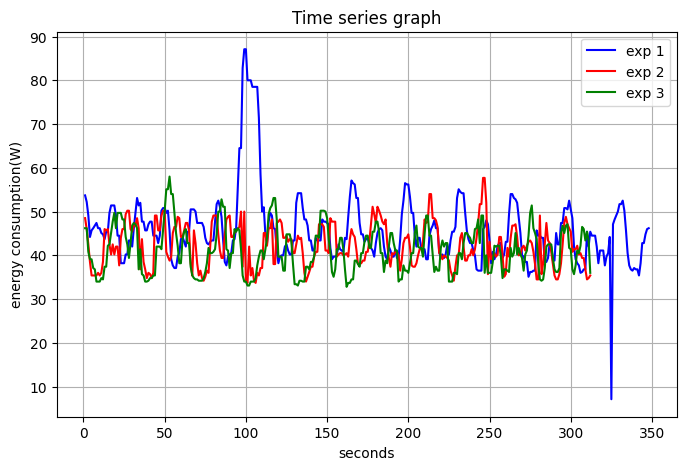

mean of smart meter is: 49.385416666666664
std of smart meter is: 7.776151175093119
mean of trad meter is: 43.16421810699589
std of trad meter is: 6.728955209686445


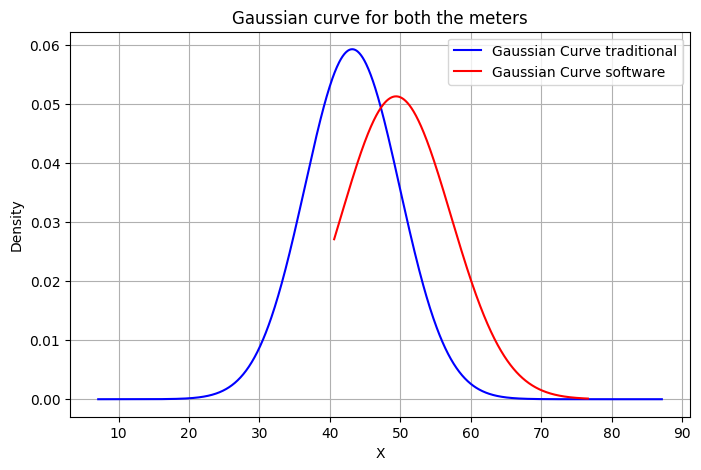

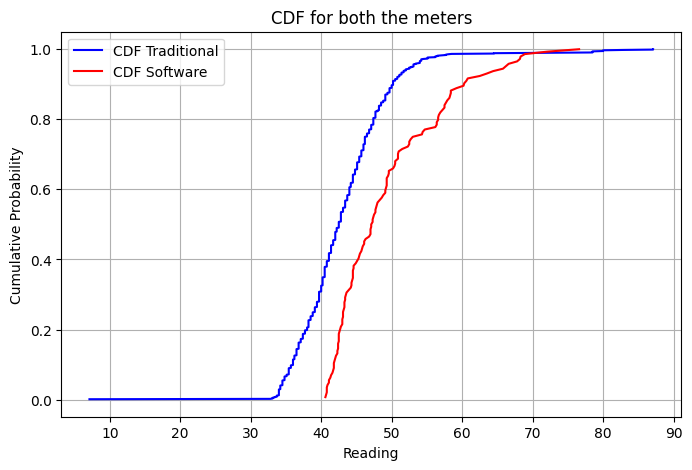

In [38]:
plot_all_graphs_everything('csv_file_traditional/traditional_meter_server_up_exp1.csv', 'csv_file_traditional/traditional_meter_server_up_exp2.csv', 'csv_file_traditional/traditional_meter_server_up_exp3.csv', 'csv_file_smart_meter/software_test_server_up_state/smart_meter_server_up_exp_1.csv', 'csv_file_smart_meter/software_test_server_up_state/smart_meter_server_up_exp_2.csv', 'csv_file_smart_meter/software_test_server_up_state/smart_meter_server_up_exp_3.csv', 2,44,2,60,2,49)

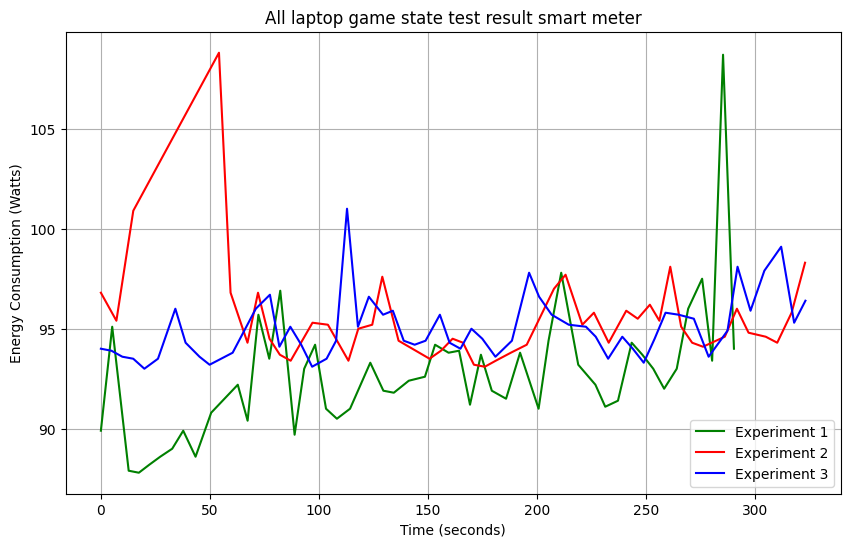

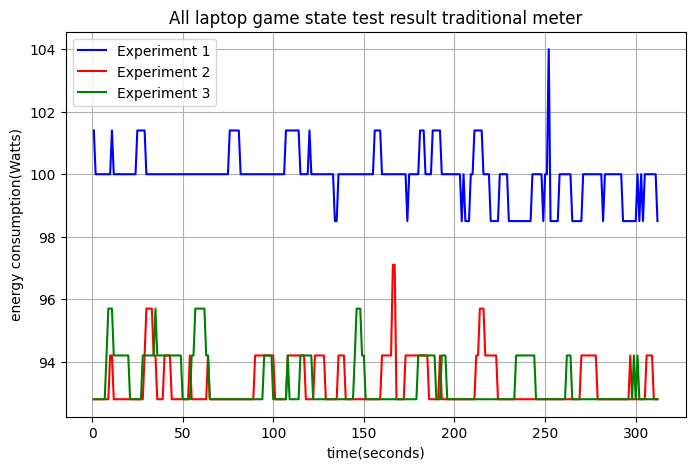

mean of smart meter is: 94.39477124183006
std of smart meter is: 2.8113910878142176
mean of trad meter is: 95.50202991452991
std of trad meter is: 3.2468966908464


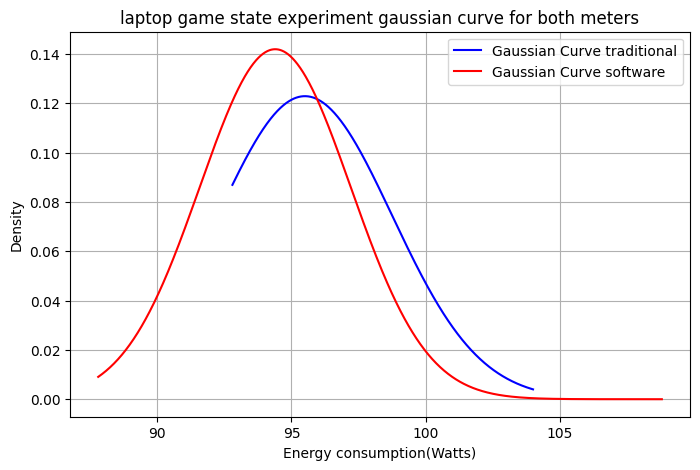

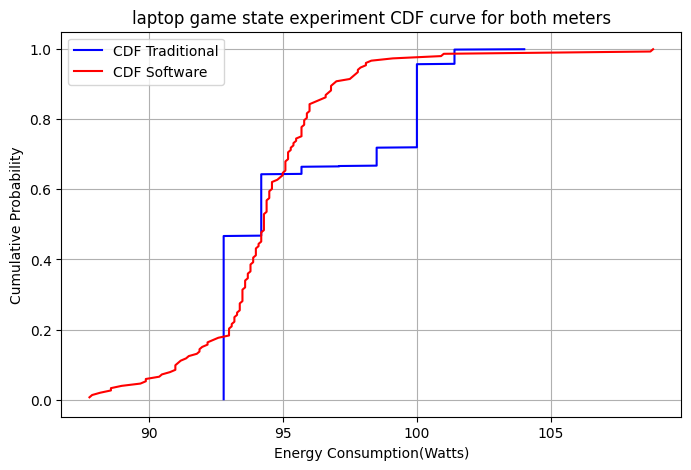

In [18]:
plot_all_graphs_everything('csv_file_traditional/traditional_meter_game_exp1.csv', 'csv_file_traditional/traditional_meter_game_exp2.csv', 'csv_file_traditional/traditional_meter_game_exp3.csv', 'csv_file_smart_meter/software_test_gaming_state/smart_meter_gaming_state_exp_1.csv', 'csv_file_smart_meter/software_test_gaming_state/smart_meter_gaming_state_exp_2.csv', 'csv_file_smart_meter/software_test_gaming_state/smart_meter_gaming_state_exp_3.csv', 2,54,2,49,2,59, "laptop game state")

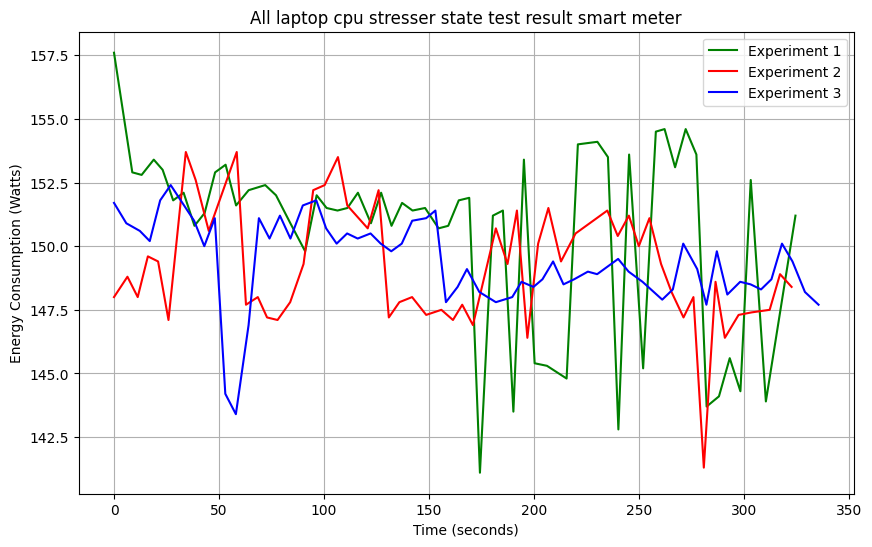

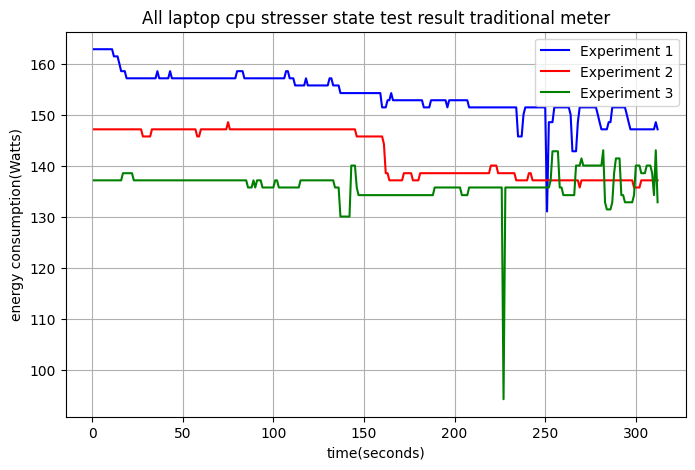

mean of smart meter is: 149.73390804597705
std of smart meter is: 2.709488724384167
mean of trad meter is: 144.1693376068376
std of trad meter is: 8.381361419239147


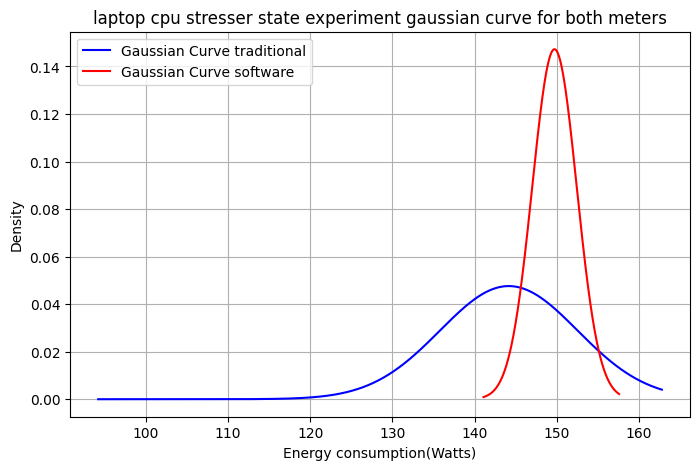

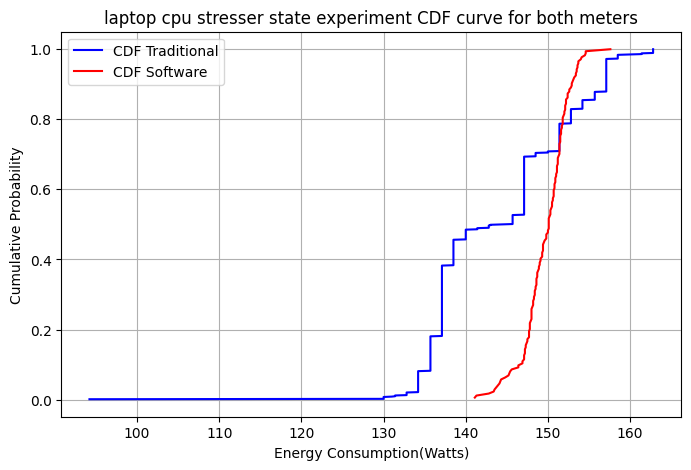

In [19]:
plot_all_graphs_everything('csv_file_traditional/traditional_meter_cpu_stresser_exp1.csv', 'csv_file_traditional/traditional_meter_cpu_stresser_exp2.csv', 'csv_file_traditional/traditional_meter_cpu_stresser_exp3.csv','csv_file_smart_meter/above_normal_threading_16_processor_state/smart_meter_above_normal_threading_16_processors_exp_1.csv', 'csv_file_smart_meter/above_normal_threading_16_processor_state/smart_meter_above_normal_threading_16_processors_exp_2.csv', 'csv_file_smart_meter/above_normal_threading_16_processor_state/smart_meter_above_normal_threading_16_processors_exp_3.csv', 2,61,2,58,2,64, "laptop cpu stresser state")